In [14]:
import sys
import json
from pathlib import Path

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT))

%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## src/config.py : fichier centrale

In [15]:
%%writefile ../src/config.py
from pathlib import Path

ROOT = Path(__file__).resolve().parents[1]
RAW_PATH = ROOT / "data" / "raw" / "students.csv"
PROCESSED_DIR = ROOT / "data" / "processed"
TRAIN_PATH = PROCESSED_DIR / "train.csv"
TEST_PATH = PROCESSED_DIR / "test.csv"
MODELS_DIR = ROOT / "models"
REPORTS_DIR = ROOT / "reports"

RANDOM_STATE = 42
TARGET = "Mental_Health_Risk"
LABELS = ["Low", "Medium", "High"]
LABEL_TO_INT = {label: i for i, label in enumerate(LABELS)}

NUMERIC_COLS = [
    "Age", "Year_of_Study", "Sleep_Hours", "Study_Hours_Per_Week", "GPA",
    "Social_Media_Hours", "Screen_Time_Hours", "Financial_Stress",
    "Family_Support", "Attendance_Rate",
]
ENGINEERED_COLS = ["Sleep_Deficit", "Non_Social_Screen_Time", "Stress_Support_Gap"]

ORDINAL_COLS = {
    "Physical_Activity": ["Low", "Moderate", "High"],
    "Diet_Quality": ["Poor", "Average", "Good"],
    "Part_Time_Job": ["No", "Yes"],
    "Previous_Mental_Health_History": ["No", "Yes"],
}
NOMINAL_COLS = ["Gender"]

INPUT_COLUMNS = NUMERIC_COLS + list(ORDINAL_COLS) + NOMINAL_COLS

VALID_RANGES = {
    "Age": (16, 40),
    "Year_of_Study": (1, 5),
    "Sleep_Hours": (2, 12),
    "Study_Hours_Per_Week": (0, 80),
    "GPA": (0, 4),
    "Social_Media_Hours": (0, 16),
    "Screen_Time_Hours": (0, 18),
    "Financial_Stress": (1, 10),
    "Family_Support": (1, 10),
    "Attendance_Rate": (0, 100),
}

Overwriting ../src/config.py


## src/utils.py

In [16]:
%%writefile ../src/utils.py
import pandas as pd
from src.config import TARGET, LABEL_TO_INT


def load_xy(path):
    df = pd.read_csv(path)
    X = df.drop(columns=[TARGET])
    y = df[TARGET].map(LABEL_TO_INT)
    return X, y

Overwriting ../src/utils.py


## src/preprocessing.py

In [17]:
import numpy as np
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (FunctionTransformer, OneHotEncoder, OrdinalEncoder, StandardScaler)

from src.config import (NUMERIC_COLS, ENGINEERED_COLS, ORDINAL_COLS, NOMINAL_COLS)


def add_features(df):
    df = df.copy()
    df["Sleep_Deficit"] = (7 - df["Sleep_Hours"]).clip(lower=0)
    df["Non_Social_Screen_Time"] = (
        df["Screen_Time_Hours"] - df["Social_Media_Hours"]).clip(lower=0)
    df["Stress_Support_Gap"] = df["Financial_Stress"] - df["Family_Support"]
    return df


class IQRClipper(BaseEstimator, TransformerMixin):

    def __init__(self, factor=1.5):
        self.factor = factor

    def fit(self, X, y=None):
        X = np.asarray(X, dtype=float)
        q1, q3 = np.percentile(X, [25, 75], axis=0)
        iqr = q3 - q1
        self.lower_ = q1 - self.factor * iqr
        self.upper_ = q3 + self.factor * iqr
        return self

    def transform(self, X):
        return np.clip(np.asarray(X, dtype=float), self.lower_, self.upper_)



def build_preprocessor():
    numeric = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("clipper", IQRClipper(factor=1.5)),
        ("scaler", StandardScaler()),
    ])
    ordinal = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OrdinalEncoder(
            categories=list(ORDINAL_COLS.values()),
            handle_unknown="use_encoded_value", unknown_value=-1,
        )),
    ])
    nominal = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ])
    return ColumnTransformer([
        ("num", numeric, NUMERIC_COLS + ENGINEERED_COLS),
        ("ord", ordinal, list(ORDINAL_COLS)),
        ("nom", nominal, NOMINAL_COLS),
    ])


def build_feature_prep():
    return Pipeline([
        ("features", FunctionTransformer(add_features)),
        ("preprocessor", build_preprocessor()),
    ])


def build_pipeline(model):
    return Pipeline([
        ("prep", build_feature_prep()),
        ("model", model),
    ])

## nettoyage et split 80/20

In [18]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

from src.config import *

def clean(df):
    df = df.drop(columns=["Student_ID"], errors="ignore")


    for col in df.columns:
        if pd.api.types.is_string_dtype(df[col]):
            df[col] = df[col].str.strip()

    df = df.drop_duplicates()
    df = df.dropna(subset=[TARGET])

    for col, (low, high) in VALID_RANGES.items():
        invalid = df[col].notna() & ~df[col].between(low, high)
        print(f"{col}: {invalid.sum()} valeur(s) hors bornes")
        df.loc[invalid, col] = np.nan
    return df

raw = pd.read_csv(RAW_PATH)
print("Avant nettoyage :", raw.shape)

df = clean(raw)
print("=============================================")
print("Après nettoyage :", df.shape)

PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
train, test = train_test_split(
    df, test_size=0.2, stratify=df[TARGET], random_state=RANDOM_STATE)

train.to_csv(TRAIN_PATH, index=False)
test.to_csv(TEST_PATH, index=False)

print("Train :", train.shape, "| Test :", test.shape)

Avant nettoyage : (2000, 17)
Age: 0 valeur(s) hors bornes
Year_of_Study: 0 valeur(s) hors bornes
Sleep_Hours: 0 valeur(s) hors bornes
Study_Hours_Per_Week: 0 valeur(s) hors bornes
GPA: 0 valeur(s) hors bornes
Social_Media_Hours: 0 valeur(s) hors bornes
Screen_Time_Hours: 0 valeur(s) hors bornes
Financial_Stress: 0 valeur(s) hors bornes
Family_Support: 0 valeur(s) hors bornes
Attendance_Rate: 0 valeur(s) hors bornes
Après nettoyage : (2000, 16)
Train : (1600, 16) | Test : (400, 16)


## vérification du split

In [19]:
print("Répartition des classes (train) :")
print(train[TARGET].value_counts(normalize=True).round(3))
print("\nRépartition des classes (test) :")
print(test[TARGET].value_counts(normalize=True).round(3))
print("\nManquants dans le train (%) :")
print((train.isna().mean() * 100).round(2).loc[lambda s: s > 0])

Répartition des classes (train) :
Mental_Health_Risk
High      0.34
Medium    0.33
Low       0.33
Name: proportion, dtype: float64

Répartition des classes (test) :
Mental_Health_Risk
High      0.34
Medium    0.33
Low       0.33
Name: proportion, dtype: float64

Manquants dans le train (%) :
Sleep_Hours           3.38
GPA                   2.25
Social_Media_Hours    3.00
Financial_Stress      4.75
Family_Support        2.25
Attendance_Rate       2.44
Diet_Quality          3.44
dtype: float64


## tester du préprocesseur et le sauvegarder

In [20]:
import joblib
from src.config import MODELS_DIR
from src.preprocessing import build_feature_prep
from src.utils import load_xy

X_train, y_train = load_xy(TRAIN_PATH)
X_test, y_test = load_xy(TEST_PATH)

prep = build_feature_prep()
X_t = prep.fit_transform(X_train)

MODELS_DIR.mkdir(exist_ok=True)
joblib.dump(prep, MODELS_DIR / "preprocessor.joblib")

['C:\\Users\\Youcode\\PycharmProjects\\Brief_Croise1\\models\\preprocessor.joblib']

## comparer les 3 modèles (baseline)

In [21]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_validate
from xgboost import XGBClassifier

from src.config import RANDOM_STATE
from src.preprocessing import build_pipeline

SCORING = {
    "accuracy": "accuracy",
    "precision": "precision_weighted",
    "recall": "recall_weighted",
    "f1": "f1_weighted",
    "roc_auc": "roc_auc_ovr_weighted",
}

MODELS = {
    "Logistic Regression": LogisticRegression(max_iter=2000),
    "Random Forest": RandomForestClassifier(random_state=RANDOM_STATE),
    "XGBoost": XGBClassifier(random_state=RANDOM_STATE, eval_metric="mlogloss"),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

rows = []
for name, model in MODELS.items():
    res = cross_validate(build_pipeline(model), X_train, y_train,
                         cv=cv, scoring=SCORING, n_jobs=-1)
    row = {"model": name, "stage": "baseline"}
    row.update({m: res[f"test_{m}"].mean() for m in SCORING})
    rows.append(row)

baseline = pd.DataFrame(rows).sort_values("f1", ascending=False)
baseline.round(3)

,model,stage,accuracy,precision,recall,f1,roc_auc
0,Logistic Regression,baseline,0.753,0.754,0.753,0.752,0.905
2,XGBoost,baseline,0.679,0.678,0.679,0.678,0.855
1,Random Forest,baseline,0.678,0.674,0.678,0.675,0.848


## optimisation des 2 meilleurs modèles

In [22]:
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV

PARAM_SPACES = {
    "Logistic Regression": {"model__C": [0.01, 0.1, 1, 10, 100]},
    "Random Forest": {
        "model__n_estimators": [200, 400, 600],
        "model__max_depth": [None, 5, 10, 20],
        "model__min_samples_leaf": [1, 2, 5],
    },
    "XGBoost": {
        "model__n_estimators": [100, 200, 400],
        "model__max_depth": [2, 3, 4, 6],
        "model__learning_rate": [0.01, 0.05, 0.1, 0.2],
        "model__subsample": [0.7, 0.85, 1.0],
    },
}

def make_search(name, pipe):
    common = {"scoring": SCORING, "refit": "f1", "cv": cv, "n_jobs": -1}

    if name == "Logistic Regression":
        return GridSearchCV(pipe, PARAM_SPACES[name], **common)
    return RandomizedSearchCV(pipe, PARAM_SPACES[name], n_iter=20,
                              random_state=RANDOM_STATE, **common)

best_search, best_name = None, None
tuned_rows = []

for name in baseline["model"].head(2):
    search = make_search(name, build_pipeline(MODELS[name]))
    search.fit(X_train, y_train)

    i = search.best_index_
    row = {"model": name, "stage": "tuned"}
    row.update({m: search.cv_results_[f"mean_test_{m}"][i] for m in SCORING})
    row["best_params"] = json.dumps(search.best_params_, default=str)
    tuned_rows.append(row)
    print(f"{name}: F1 = {search.best_score_:.3f} | {search.best_params_}")

    if best_search is None or search.best_score_ > best_search.best_score_:
        best_search, best_name = search, name

results = pd.concat([baseline, pd.DataFrame(tuned_rows)], ignore_index=True)
display(results.round(3))
print("Meilleur modèle :", best_name)

Logistic Regression: F1 = 0.752 | {'model__C': 10}
XGBoost: F1 = 0.711 | {'model__subsample': 0.7, 'model__n_estimators': 400, 'model__max_depth': 2, 'model__learning_rate': 0.1}


,model,stage,accuracy,precision,recall,f1,roc_auc,best_params
0,Logistic Regression,baseline,0.753,0.754,0.753,0.752,0.905,NaN
1,XGBoost,baseline,0.679,0.678,0.679,0.678,0.855,NaN
2,Random Forest,baseline,0.678,0.674,0.678,0.675,0.848,NaN
3,Logistic Regression,tuned,0.752,0.754,0.752,0.752,0.905,"{""model__C"": 10}"
4,XGBoost,tuned,0.711,0.712,0.711,0.711,0.877,"{""model__subsample"": 0.7, ""model__n_estimators..."


Meilleur modèle : Logistic Regression


## sauvegarder le meilleur pipeline

In [23]:
from src.config import REPORTS_DIR

REPORTS_DIR.mkdir(exist_ok=True)

joblib.dump(best_search.best_estimator_, MODELS_DIR / "best_pipeline.joblib")
results.to_csv(REPORTS_DIR / "cv_results.csv", index=False)

with open(REPORTS_DIR / "best_model.json", "w") as f:
    json.dump({"model": best_name,
               "cv_f1_weighted": best_search.best_score_,
               "params": best_search.best_params_}, f, indent=2, default=str)
print("Sauvegardé dans models/ et reports/")

Sauvegardé dans models/ et reports/


## évaluation sur le jeu de test

In [24]:
import matplotlib.pyplot as plt
from sklearn.metrics import (
    ConfusionMatrixDisplay, accuracy_score, classification_report,
    f1_score, precision_score, recall_score, roc_auc_score,
)
from src.config import LABELS

pipe = joblib.load(MODELS_DIR / "best_pipeline.joblib")
y_pred = pipe.predict(X_test)
proba = pipe.predict_proba(X_test)

metrics = {
    "accuracy": accuracy_score(y_test, y_pred),
    "precision_weighted": precision_score(y_test, y_pred, average="weighted"),
    "recall_weighted": recall_score(y_test, y_pred, average="weighted"),
    "f1_weighted": f1_score(y_test, y_pred, average="weighted"),
    "f1_macro": f1_score(y_test, y_pred, average="macro"),
    "roc_auc_ovr": roc_auc_score(y_test, proba, multi_class="ovr", average="weighted"),
    "report": classification_report(y_test, y_pred, target_names=LABELS, output_dict=True),
}
print({k: round(v, 3) for k, v in metrics.items() if isinstance(v, float)})
print(classification_report(y_test, y_pred, target_names=LABELS))

{'accuracy': 0.757, 'precision_weighted': 0.758, 'recall_weighted': 0.757, 'f1_weighted': 0.757, 'f1_macro': 0.757, 'roc_auc_ovr': 0.913}
              precision    recall  f1-score   support

         Low       0.82      0.80      0.81       132
      Medium       0.64      0.64      0.64       132
        High       0.81      0.83      0.82       136

    accuracy                           0.76       400
   macro avg       0.76      0.76      0.76       400
weighted avg       0.76      0.76      0.76       400



## matrice de confusion

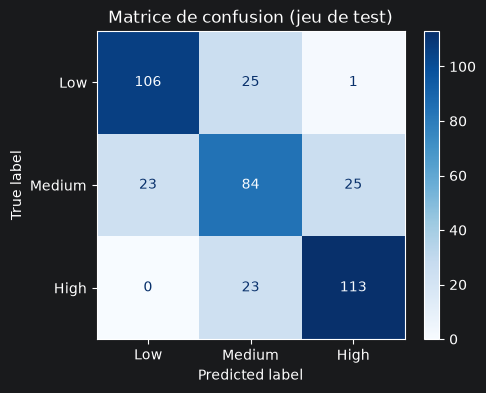

In [28]:
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=LABELS,
    cmap="Blues",
    ax=ax
)
ax.set_title("Matrice de confusion (jeu de test)")
fig.savefig(REPORTS_DIR / "confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

## Courbe ROC-AUC multiclasse

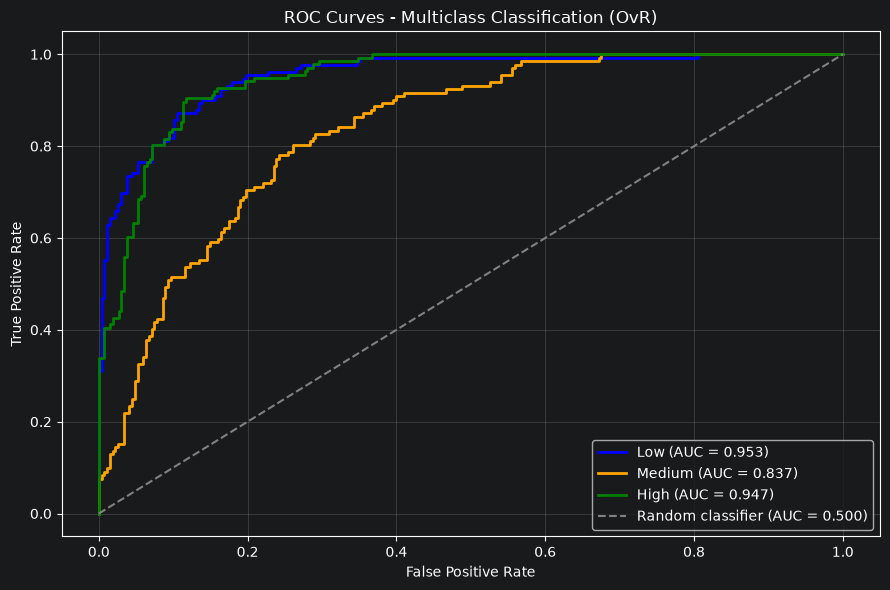

In [33]:
import matplotlib.pyplot as plt
import numpy as np

from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize


y_test_bin = label_binarize(y_test, classes=[0, 1, 2])

colors = ["blue", "orange", "green"]

plt.figure(figsize=(9, 6))


for i, label in enumerate(LABELS):

    fpr, tpr, thresholds = roc_curve(y_test_bin[:, i], proba[:, i])
    roc_auc = auc(fpr, tpr)

    plt.plot(
        fpr,
        tpr,
        color=colors[i],
        linewidth=2,
        label=f"{label} (AUC = {roc_auc:.3f})"
    )


plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray",
    label="Random classifier (AUC = 0.500)"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves - Multiclass Classification (OvR)")

plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(REPORTS_DIR / "roc_curve.png", dpi=150, bbox_inches="tight")

plt.show()

## analyse des erreurs


In [29]:
wrong = y_test.values != y_pred
metrics["n_errors"] = int(wrong.sum())

metrics["n_severe_errors"] = int(((y_test.values - y_pred) ** 2 == 4).sum())
print(f"Erreurs : {metrics['n_errors']} / {len(y_test)} | graves (Low<->High) : {metrics['n_severe_errors']}")

errors = X_test[wrong].copy()
errors["true"] = [LABELS[i] for i in y_test.values[wrong]]
errors["pred"] = [LABELS[i] for i in y_pred[wrong]]
errors.to_csv(REPORTS_DIR / "errors.csv", index=False)
errors.head(10)

Erreurs : 97 / 400 | graves (Low<->High) : 1


,Age,Gender,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Physical_Activity,Financial_Stress,Family_Support,Attendance_Rate,Part_Time_Job,Diet_Quality,Previous_Mental_Health_History,true,pred
2,22.0,Female,4.0,5.9,21.7,2.23,6.1,9.0,Moderate,3.1,9.4,86.5,Yes,Poor,No,Low,Medium
3,25.0,Male,1.0,6.9,19.7,2.35,6.4,8.8,Low,6.8,7.2,75.3,Yes,Poor,No,Medium,High
9,23.0,Male,1.0,7.8,4.9,2.15,6.3,9.9,Low,6.1,5.9,78.7,Yes,Good,No,High,Medium
11,22.0,Female,3.0,8.4,18.5,2.47,5.8,8.1,High,3.0,3.4,75.7,No,Poor,No,Medium,Low
12,22.0,Male,1.0,6.1,17.9,2.22,5.5,8.7,High,2.4,7.7,87.9,Yes,Average,No,Medium,Low
17,21.0,Male,5.0,6.5,22.5,2.38,NaN,7.9,High,6.5,8.8,84.7,No,Average,No,Medium,Low
26,21.0,Female,5.0,6.3,25.6,2.60,6.9,8.3,Moderate,4.6,6.2,84.5,No,Good,No,Medium,Low
27,22.0,Male,3.0,6.2,15.1,2.64,8.0,10.5,Low,4.3,4.8,82.1,No,Average,No,Medium,High
38,22.0,Female,1.0,8.3,14.3,2.37,7.2,7.6,Moderate,5.4,NaN,71.2,No,Average,No,Medium,Low
40,19.0,Female,2.0,6.9,19.8,2.49,3.8,6.7,High,2.8,4.5,79.5,No,Average,Yes,Medium,Low


## importance des variables

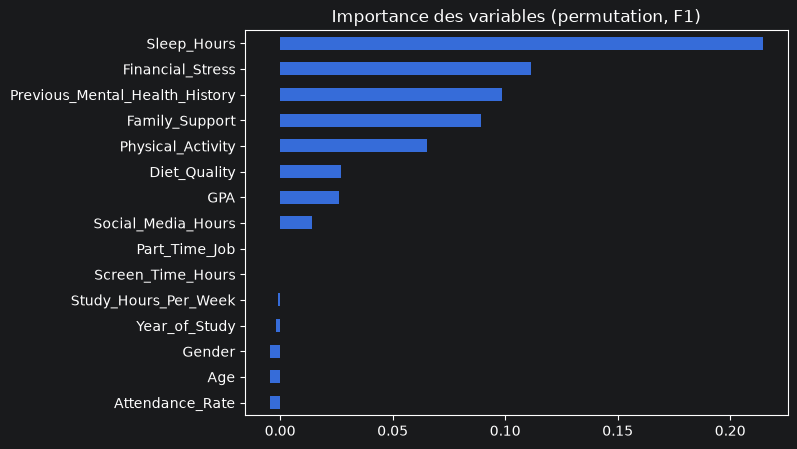

In [34]:
from sklearn.inspection import permutation_importance

r = permutation_importance(pipe, X_test, y_test, scoring="f1_weighted",
                           n_repeats=10, random_state=RANDOM_STATE, n_jobs=-1)
imp = pd.Series(r.importances_mean, index=X_test.columns).sort_values()
imp.to_csv(REPORTS_DIR / "feature_importance.csv")

fig, ax = plt.subplots(figsize=(7, 5))
imp.plot(kind="barh", ax=ax, title="Importance des variables (permutation, F1)")
fig.savefig(REPORTS_DIR / "feature_importance.png", dpi=150, bbox_inches="tight")
plt.show()

## sauvegarder les métriques et tester le pipeline

In [35]:
with open(REPORTS_DIR / "metrics.json", "w") as f:
    json.dump(metrics, f, indent=2)

# Test de bout en bout : un étudiant brut -> prédiction
exemple = X_test.iloc[[0]]
print("Données :\n", exemple.T)
print("Prédit :", LABELS[pipe.predict(exemple)[0]], "| Réel :", LABELS[y_test.iloc[0]])

Données :
                                    0
Age                             24.0
Gender                          Male
Year_of_Study                    5.0
Sleep_Hours                      5.2
Study_Hours_Per_Week            28.1
GPA                             3.31
Social_Media_Hours               5.7
Screen_Time_Hours                7.7
Physical_Activity                Low
Financial_Stress                 6.4
Family_Support                   6.0
Attendance_Rate                 76.2
Part_Time_Job                     No
Diet_Quality                    Good
Previous_Mental_Health_History   Yes
Prédit : High | Réel : High
